# Klasifikasi Citra Sepatu: Berantakan vs Rapi — Ekstraksi Fitur dan Klasifikasi

Fitur yang diekstraksi dari setiap citra:

| Kelompok | Fitur | Rumus (slide / jurnal) |
|---|---|---|
| Warna (RGB) | `mean_r`, `mean_g`, `mean_b` | Pers. (2) |
| Warna (RGB) | `std_r`, `std_g`, `std_b` | Pers. (3) |
| Warna (RGB) | `skew_r`, `skew_g`, `skew_b` | Pers. (4) |
| Tekstur (GLCM, grayscale) | `energi` | Pers. (8) |
| Tekstur (GLCM, grayscale) | `entropi` | Pers. (5) |
| Tekstur (GLCM, grayscale) | `kontras` | Pers. (6) |
| Tekstur (GLCM, grayscale) | `korelasi` | Pers. (7) |
| Tekstur (GLCM, grayscale) | `homogenitas` | Pers. (9) |
| Target | `label` | `berantakan` / `rapi` |

Hasil akhir disimpan ke `data/processed/fitur_lengkap.csv`.

Setelah itu (Bab 11–13), fitur tersebut dipakai untuk klasifikasi (14 fitur sesuai ketentuan; 24 fitur tambahan yang disesuaikan dengan karakter foto bersifat opsional, lihat Bab 9 dan 14) dengan **7 metode** (Random Forest, SVM, KNN, Logistic Regression, Decision Tree, Naive Bayes, Gradient Boosting), lengkap dengan *confusion matrix* dan akurasi, dengan alur yang sama seperti klasifikasi audio.

## 1. Import Library

In [23]:
import os
import io
import glob
import zipfile

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

## 2. Pilih File Dataset
Dataset dipilih langsung lewat tombol **Choose Files**, tanpa folder atau path. Bisa berupa:
- file zip, misalnya `berantakan.zip` dan `rapi.zip` (pilih keduanya sekaligus), **atau**
- gambar satuan (`.jpg`, `.png`, dll.) yang nama filenya mengandung kata `berantakan` / `rapi`.

Tombol muncul saat sel di bawah dijalankan. Di Google Colab muncul tombol *Choose Files*, sedangkan di Jupyter lokal muncul jendela pilih file.

In [24]:
import io, zipfile

UKURAN_RESIZE = (256, 256)          # semua gambar disamakan ukurannya
EKSTENSI = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".jfif")

# Parameter GLCM: jarak d = 1, sudut θ = 0° (tetangga kanan), 256 level keabuan
GLCM_DX, GLCM_DY, GLCM_LEVEL = 1, 0, 256

FOLDER_OUTPUT = "data/processed"    # tempat CSV hasil (dibuat otomatis)
os.makedirs(FOLDER_OUTPUT, exist_ok=True)

def pilih_file():
    """Tampilkan dialog pilih file. Kembalikan dict {nama_file: isi_bytes}."""
    try:
        from google.colab import files               # Google Colab
        return dict(files.upload())
    except ImportError:                              # Jupyter / VS Code lokal
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk(); root.withdraw(); root.attributes("-topmost", True)
        paths = filedialog.askopenfilenames(title="Pilih zip / gambar dataset")
        root.destroy()
        hasil = {}
        for pth in paths:
            with open(pth, "rb") as fh:
                hasil[os.path.basename(pth)] = fh.read()
        return hasil

berkas = pilih_file()
if not berkas:
    raise FileNotFoundError("Belum ada file yang dipilih. Jalankan ulang sel ini lalu pilih file.")
print("File dipilih:", list(berkas))

File dipilih: ['foto-psd-20261115T122617Z-1-001.zip']


## 3. Membaca Data
### 3.1 Jumlah gambar


In [25]:
def tentukan_label(teks):
    teks = teks.lower().replace("\\", "/")
    if "berantakan" in teks or "messy" in teks:
        return "berantakan"
    if "rapi" in teks or "neat" in teks or "tidy" in teks:
        return "rapi"
    return None

arsip = {}          # zip yang berhasil dibuka
kandidat = []       # (sumber, path di dalam sumber)

for nama, isi in berkas.items():
    if nama.lower().endswith(".zip"):
        try:
            arsip[nama] = zipfile.ZipFile(io.BytesIO(isi))
        except zipfile.BadZipFile:
            print(f"ZIP RUSAK, dilewati: {nama}")
            continue
        for p in sorted(arsip[nama].namelist()):
            base = os.path.basename(p)
            if p.endswith("/") or "__MACOSX" in p or base.startswith("._"):
                continue                    # lewati folder & file sampah Mac
            if base.lower().endswith(EKSTENSI):
                kandidat.append((nama, p))
    elif nama.lower().endswith(EKSTENSI):
        kandidat.append((nama, nama))       # gambar satuan
    else:
        print(f"Dilewati (bukan zip/gambar): {nama}")

def baca_bytes(sumber, path):
    if sumber in arsip:
        return arsip[sumber].read(path)
    return berkas[sumber]

data, rusak = [], []
for sumber, path in kandidat:
    try:
        Image.open(io.BytesIO(baca_bytes(sumber, path))).verify()   # cek gambar utuh
    except Exception as e:
        rusak.append({"sumber": sumber, "path": path, "error": type(e).__name__})
        continue
    label = tentukan_label(path) or tentukan_label(sumber)
    data.append({"sumber": sumber, "path": path, "nama_file": os.path.basename(path), "label": label})

df = pd.DataFrame(data, columns=["sumber", "path", "nama_file", "label"])
rusak = pd.DataFrame(rusak, columns=["sumber", "path", "error"])

if df["label"].isna().any():
    print("PERINGATAN: gambar berikut labelnya tidak dikenali dan DIBUANG")
    print("(beri nama file/zip yang mengandung 'berantakan' atau 'rapi'):")
    print(df[df["label"].isna()]["path"].head().to_string(), "\n")
    df = df[df["label"].notna()].reset_index(drop=True)

print("Total gambar terbaca :", len(df))
print("Gambar dilewati      :", len(rusak))
print()
print(df["label"].value_counts(dropna=False))

if len(rusak):
    print("\nPERINGATAN: file berikut tidak bisa dibaca dan dilewati")
    print(rusak.groupby(["sumber", "error"]).size().rename("jumlah").to_string())
if df["label"].nunique() < 2:
    raise ValueError("Hanya ada kurang dari 2 kelas. Pilih juga dataset kelas lainnya.")

Total gambar terbaca : 194
Gambar dilewati      : 0

label
berantakan    97
rapi          97
Name: count, dtype: int64


### 3.2 Contoh gambar asli

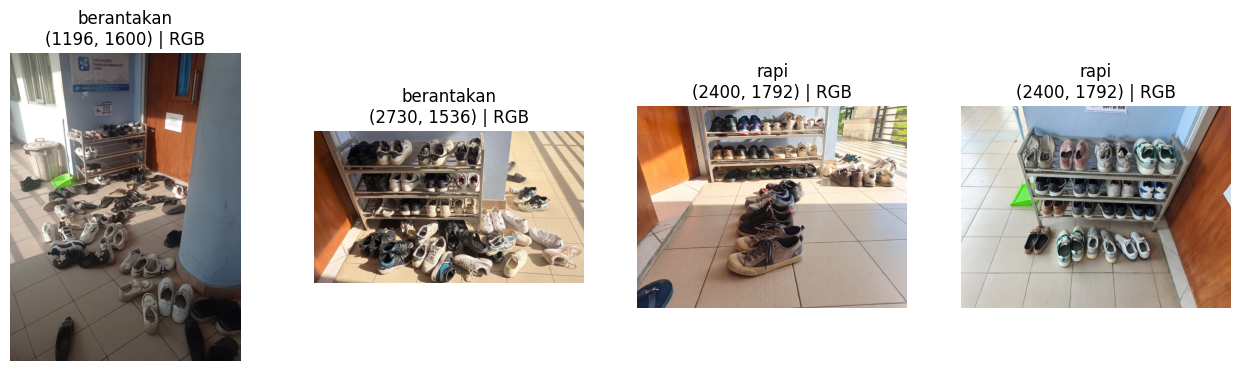

In [26]:
def buka_gambar(idx):
    """Baca gambar ke-idx dari zip/folder ke memori."""
    row = df.loc[idx]
    return Image.open(io.BytesIO(baca_bytes(row["sumber"], row["path"])))

contoh = pd.concat([df[df.label == "berantakan"].head(2), df[df.label == "rapi"].head(2)])
fig, axes = plt.subplots(1, len(contoh), figsize=(4 * len(contoh), 4), squeeze=False)
for ax, (idx, row) in zip(axes[0], contoh.iterrows()):
    img = buka_gambar(idx)
    ax.imshow(img)
    ax.set_title(f"{row['label']}\n{img.size} | {img.mode}")
    ax.axis("off")
plt.show()

## 4. Preprocessing
1. **Konversi ke RGB** — gambar PNG (RGBA) atau grayscale disamakan menjadi 3 kanal.
2. **Resize** — semua gambar disamakan ukurannya menjadi 256 × 256 piksel.

In [27]:
def preprocessing(idx):
    img = buka_gambar(idx)
    img = img.convert("RGB")                  # 1. konversi RGB
    img = img.resize(UKURAN_RESIZE)           # 2. resize
    return np.array(img, dtype=np.float64)    # array (256, 256, 3)

# Preprocessing semua gambar sekali saja, disimpan di memori
citra_rgb = {idx: preprocessing(idx) for idx in df.index}

arr = citra_rgb[0]
print("Jumlah citra               :", len(citra_rgb))
print("Shape setelah preprocessing:", arr.shape)
print("Nilai piksel min - max     :", arr.min(), "-", arr.max())

Jumlah citra               : 194
Shape setelah preprocessing: (256, 256, 3)
Nilai piksel min - max     : 6.0 - 255.0


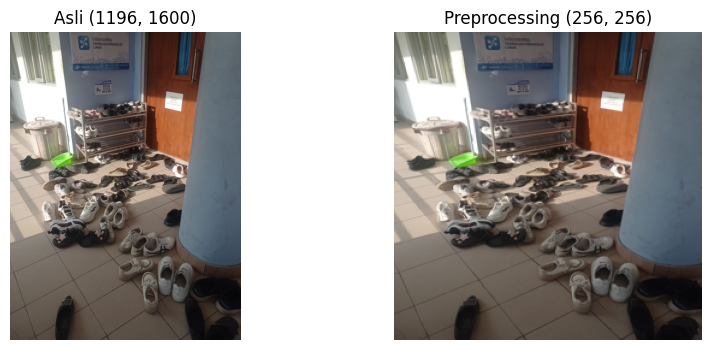

In [28]:
# Sebelum vs sesudah preprocessing
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
asli = buka_gambar(0)
axes[0].imshow(asli);                       axes[0].set_title(f"Asli {asli.size}")
axes[1].imshow(citra_rgb[0].astype(np.uint8)); axes[1].set_title(f"Preprocessing {UKURAN_RESIZE}")
for ax in axes: ax.axis("off")
plt.show()

## 5. Ekstraksi Fitur Warna: Mean, Std, Skewness tiap Kanal

$$\mu_C = \frac{1}{MN}\sum_{i=1}^{M}\sum_{j=1}^{N} I_C(i,j) \quad\text{Pers. (2)}$$

$$\sigma_C = \sqrt{\frac{1}{MN}\sum_{i,j}\big(I_C(i,j)-\mu_C\big)^2} \quad\text{Pers. (3)}$$

$$\text{Skewness}_C = \frac{1}{MN}\sum_{i,j}\left(\frac{I_C(i,j)-\mu_C}{\sigma_C}\right)^3 \quad\text{Pers. (4)}$$

dengan $C \in \{R, G, B\}$ dan $M \times N$ = jumlah piksel.
Skewness positif = distribusi menceng ke kanan (banyak piksel gelap, sedikit yang terang); negatif = menceng ke kiri.

In [29]:
def mean_kanal(k):
    return k.sum() / k.size                                  # Pers. (2)

def std_kanal(k):
    mu = mean_kanal(k)
    return np.sqrt(np.sum((k - mu) ** 2) / k.size)           # Pers. (3)

def skew_kanal(k):
    mu, sd = mean_kanal(k), std_kanal(k)
    if sd == 0:
        return 0.0                                           # citra polos: tidak menceng
    return np.sum(((k - mu) / sd) ** 3) / k.size             # Pers. (4)

# Contoh perhitungan untuk 1 gambar
idx = 0
arr = citra_rgb[idx]
print("Gambar :", df.loc[idx, "path"], "| label:", df.loc[idx, "label"], "\n")
for i, nama in enumerate("RGB"):
    k = arr[:, :, i]
    print(f"Kanal {nama}: mean = {mean_kanal(k):9.4f} | std = {std_kanal(k):8.4f} | skew = {skew_kanal(k):8.4f}")

# Cek: hasil manual harus sama dengan numpy / scipy
from scipy.stats import skew as scipy_skew
k = arr[:, :, 0]
print("\nCek kanal R dengan library:")
print("  numpy mean :", round(k.mean(), 4), "| numpy std:", round(k.std(), 4),
      "| scipy skew:", round(scipy_skew(k.ravel()), 4))

Gambar : foto-psd/berantakan/24-003 Berantakan 2.jpg | label: berantakan 

Kanal R: mean =  108.5442 | std =  55.0561 | skew =   0.8111
Kanal G: mean =  101.3958 | std =  53.7121 | skew =   0.8241
Kanal B: mean =   96.5326 | std =  52.8137 | skew =   0.7943

Cek kanal R dengan library:
  numpy mean : 108.5442 | numpy std: 55.0561 | scipy skew: 0.8111


In [30]:
hasil = []
for idx, row in df.iterrows():
    arr = citra_rgb[idx]
    baris = {"id": idx + 1, "nama_file": row["nama_file"]}
    for stat, fungsi in [("mean", mean_kanal), ("std", std_kanal), ("skew", skew_kanal)]:
        for i, nama in enumerate("rgb"):
            baris[f"{stat}_{nama}"] = round(fungsi(arr[:, :, i]), 4)
    baris["label"] = row["label"]
    hasil.append(baris)

tabel = pd.DataFrame(hasil)
tabel.to_csv(os.path.join(FOLDER_OUTPUT, "fitur_warna.csv"), index=False)
print("Disimpan ke:", os.path.abspath(os.path.join(FOLDER_OUTPUT, "fitur_warna.csv")))
tabel.head()

Disimpan ke: c:\Users\LALIR\Documents\s5\PSD IF5A\image-classification\data\processed\fitur_warna.csv


,id,nama_file,mean_r,mean_g,mean_b,std_r,std_g,std_b,skew_r,skew_g,skew_b,label
0,1,24-003 Berantakan 2.jpg,108.5442,101.3958,96.5326,55.0561,53.7121,52.8137,0.8111,0.8241,0.7943,berantakan
1,2,24-003 Berantakan 3.jpg,149.4176,129.9941,112.1718,72.8466,69.7848,63.4107,-0.2158,-0.1189,-0.1042,berantakan
2,3,24-003 berantakan.jpg,144.5782,109.8351,85.6104,70.3410,57.7117,53.7634,-0.0283,0.2784,0.6641,berantakan
3,4,24-006 Berantakan 1.jpg,120.5385,112.6790,109.4066,53.0531,51.0577,50.7295,-0.5030,-0.2669,-0.1847,berantakan
4,5,24-006 Berantakan 2.jpg,126.6296,119.9131,116.6886,54.1044,50.0877,48.7256,-0.7745,-0.5788,-0.4273,berantakan


## 6. Konversi ke Grayscale
$$Gray = 0.299R + 0.587G + 0.114B$$
Hasilnya dibulatkan menjadi 8 bit (nilai 0–255), jadi ada 256 level keabuan.

Jumlah citra grayscale : 194
Level keabuan          : 2^8 = 256 (nilai 0 - 255)

Gambar : foto-psd/berantakan/24-003 Berantakan 2.jpg | label: berantakan
Shape RGB  : (256, 256, 3) -> Shape gray: (256, 256)
Tipe data  : uint8 | min: 6 | max: 255

Piksel (0,0): R=98, G=101, B=90
Gray = 0.299*98 + 0.587*101 + 0.114*90 = 98.85 -> 99

Nilai gray (5x5 piksel pertama):
     0    1    2    3    4
0   99  120  156  155  155
1  102  113  155  156  155
2  102  108  148  158  156
3   99  105  138  160  158
4   98  105  126  160  160


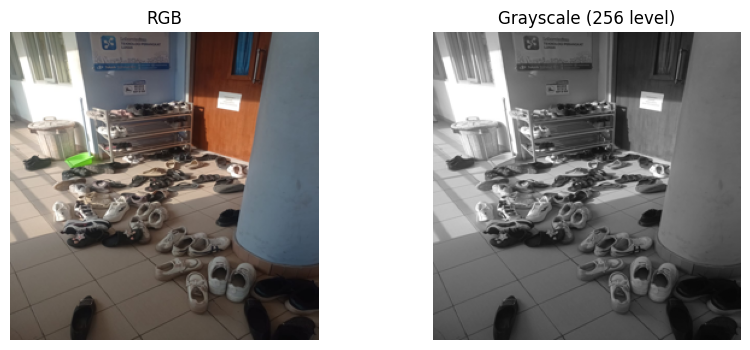

In [31]:
def rgb_ke_gray(arr):
    R, G, B = arr[:, :, 0], arr[:, :, 1], arr[:, :, 2]
    gray = 0.299 * R + 0.587 * G + 0.114 * B
    return np.clip(np.round(gray), 0, 255).astype(np.uint8)   # 8 bit: 0-255

citra_gray = {idx: rgb_ke_gray(arr) for idx, arr in citra_rgb.items()}

print("Jumlah citra grayscale :", len(citra_gray))
print("Level keabuan          : 2^8 =", 2**8, "(nilai 0 - 255)")

idx = 0
arr, gray = citra_rgb[idx], citra_gray[idx]
print("\nGambar :", df.loc[idx, "path"], "| label:", df.loc[idx, "label"])
print("Shape RGB  :", arr.shape, "-> Shape gray:", gray.shape)
print("Tipe data  :", gray.dtype, "| min:", gray.min(), "| max:", gray.max())

r, g, b = arr[0, 0]
print(f"\nPiksel (0,0): R={r:.0f}, G={g:.0f}, B={b:.0f}")
print(f"Gray = 0.299*{r:.0f} + 0.587*{g:.0f} + 0.114*{b:.0f} = {0.299*r + 0.587*g + 0.114*b:.2f} -> {gray[0, 0]}")

n = 5
print(f"\nNilai gray ({n}x{n} piksel pertama):")
print(pd.DataFrame(gray[:n, :n]).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(arr.astype(np.uint8));                axes[0].set_title("RGB")
axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[1].set_title("Grayscale (256 level)")
for ax in axes: ax.axis("off")
plt.show()

## 7. Matriks Co-occurrence (GLCM)
GLCM mencatat seberapa sering pasangan nilai piksel (i, j) muncul pada offset tertentu.
Di sini dipakai **d = 1, θ = 0°**: piksel referensi (x, y) dipasangkan dengan tetangga kanannya (x, y+1).

1. Tabulasi frekuensi pasangan → GLCM mentah (baris = piksel asal, kolom = piksel tetangga)
2. Normalisasi: $P(i,j) = \dfrac{GLCM(i,j)}{\sum GLCM}$, sehingga jumlah semua $P(i,j) = 1$

In [32]:
def buat_glcm(gray, levels=GLCM_LEVEL, dx=GLCM_DX, dy=GLCM_DY):
    """GLCM mentah. dx=1, dy=0 -> d=1, θ=0° (tetangga kanan)."""
    h, w = gray.shape
    ref = gray[0:h - dy, 0:w - dx].ravel().astype(np.int64)   # piksel referensi
    tet = gray[dy:h, dx:w].ravel().astype(np.int64)           # piksel tetangga
    glcm = np.zeros((levels, levels), dtype=np.int64)
    np.add.at(glcm, (ref, tet), 1)                            # tabulasi frekuensi pasangan
    return glcm

def normalisasi_glcm(glcm):
    return glcm / glcm.sum()                                  # P(i,j)

# Cek dengan contoh citra 3x3 di slide (level 0, 1, 2)
contoh = np.array([[0, 1, 1],
                   [0, 2, 1],
                   [2, 2, 0]])
g = buat_glcm(contoh, levels=3)
print("GLCM mentah (contoh slide):")
print(pd.DataFrame(g).to_string())
print("\nTotal pasangan:", g.sum())
print("\nGLCM ternormalisasi P(i,j):")
print(pd.DataFrame(normalisasi_glcm(g)).round(3).to_string())

GLCM mentah (contoh slide):
   0  1  2
0  0  1  1
1  0  1  0
2  1  1  1

Total pasangan: 6

GLCM ternormalisasi P(i,j):
       0      1      2
0  0.000  0.167  0.167
1  0.000  0.167  0.000
2  0.167  0.167  0.167


Gambar : foto-psd/berantakan/24-003 Berantakan 2.jpg | label: berantakan
Ukuran GLCM     : (256, 256)
Total pasangan  : 65280 (= 256 baris x 255 pasangan per baris)
Jumlah P(i,j)   : 1.0

Potongan GLCM mentah (level 94-103):
     94   95   96   97   98   99   100  101  102  103
94   191   72   29   10    9    5    9    6    3    1
95   125  145   83   28   10    4    6    3    5    3
96    55  122  147  101   27   12    8    6    6    5
97    17   59  141  248   99   36   24    8    6   15
98    11   22   68  176  209   83   29   16   17    6
99    10    8   20   74  182  283  120   33   15    9
100    7    7   10   23   87  238  439   81   35   21
101    6    4    5    9   19   65  220  265  100   47
102    3    7    5   10   11   12   77  226  236  121
103    6    1    3    9   10    7   15   88  230  389


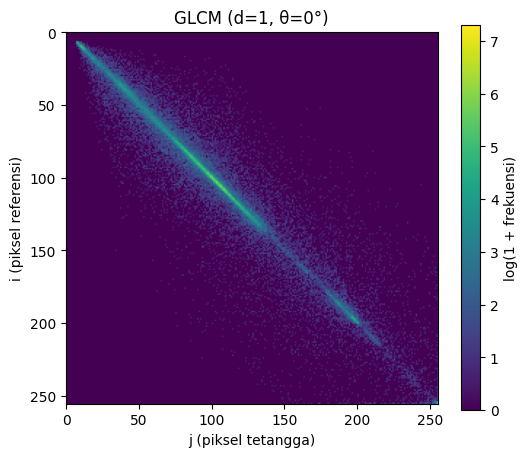

In [33]:
# Matriks co-occurrence untuk 1 gambar dataset
idx = 0
glcm = buat_glcm(citra_gray[idx])
P = normalisasi_glcm(glcm)

print("Gambar :", df.loc[idx, "path"], "| label:", df.loc[idx, "label"])
print("Ukuran GLCM     :", glcm.shape)
print("Total pasangan  :", glcm.sum(), "(= 256 baris x 255 pasangan per baris)")
print("Jumlah P(i,j)   :", round(P.sum(), 6))

# Tampilkan potongan di sekitar nilai keabuan yang paling sering muncul
pusat = int(np.median(citra_gray[idx]))
a, b = max(pusat - 5, 0), min(pusat + 5, 256)
print(f"\nPotongan GLCM mentah (level {a}-{b - 1}):")
print(pd.DataFrame(glcm[a:b, a:b], index=range(a, b), columns=range(a, b)).to_string())

plt.figure(figsize=(6, 5))
plt.imshow(np.log1p(glcm), cmap="viridis")
plt.colorbar(label="log(1 + frekuensi)")
plt.title("GLCM (d=1, θ=0°)")
plt.xlabel("j (piksel tetangga)"); plt.ylabel("i (piksel referensi)")
plt.show()

In [34]:
# Hitung matriks P(i,j) semua gambar sekali saja, dipakai untuk semua fitur tekstur
glcm_semua = {idx: normalisasi_glcm(buat_glcm(gray)) for idx, gray in citra_gray.items()}
i_idx, j_idx = np.indices((GLCM_LEVEL, GLCM_LEVEL))   # matriks indeks i dan j

def tambah_fitur(nama_kolom, fungsi):
    """Hitung fitur untuk semua gambar lalu sisipkan kolomnya sebelum kolom label."""
    nilai = [float(fungsi(glcm_semua[idx])) for idx in df.index]
    if nama_kolom in tabel.columns:
        tabel.drop(columns=nama_kolom, inplace=True)          # aman kalau sel dijalankan ulang
    tabel.insert(tabel.columns.get_loc("label"), nama_kolom, nilai)

print("GLCM siap untuk", len(glcm_semua), "gambar")

GLCM siap untuk 194 gambar


## 8. Fitur Tekstur GLCM
Setiap fitur ditambahkan satu per satu sebagai kolom baru.

### 8.1 Energi — Pers. (8)
$$Energi = \sum_{i}\sum_{j} P(i,j)^2$$
Disebut juga *Angular Second Moment*. Nilai tinggi = tekstur seragam.

In [35]:
def energi(P):
    return np.sum(P ** 2)

tambah_fitur("energi", energi)
tabel.head()

,id,nama_file,mean_r,mean_g,mean_b,std_r,std_g,std_b,skew_r,skew_g,skew_b,energi,label
0,1,24-003 Berantakan 2.jpg,108.5442,101.3958,96.5326,55.0561,53.7121,52.8137,0.8111,0.8241,0.7943,0.001497,berantakan
1,2,24-003 Berantakan 3.jpg,149.4176,129.9941,112.1718,72.8466,69.7848,63.4107,-0.2158,-0.1189,-0.1042,0.000317,berantakan
2,3,24-003 berantakan.jpg,144.5782,109.8351,85.6104,70.3410,57.7117,53.7634,-0.0283,0.2784,0.6641,0.000323,berantakan
3,4,24-006 Berantakan 1.jpg,120.5385,112.6790,109.4066,53.0531,51.0577,50.7295,-0.5030,-0.2669,-0.1847,0.000759,berantakan
4,5,24-006 Berantakan 2.jpg,126.6296,119.9131,116.6886,54.1044,50.0877,48.7256,-0.7745,-0.5788,-0.4273,0.001151,berantakan


### 8.2 Entropi — Pers. (5)
$$Entropi = -\sum_{i}\sum_{j} P(i,j)\,\log_2 P(i,j)$$
Keacakan tekstur, berkisar 0 sampai $\log_2$ jumlah sel GLCM. Sel bernilai 0 dilewati karena $\log_2 0$ tidak terdefinisi.

In [36]:
def entropi(P):
    nz = P[P > 0]
    return -np.sum(nz * np.log2(nz))

tambah_fitur("entropi", entropi)
tabel.head()

,id,nama_file,mean_r,mean_g,mean_b,std_r,std_g,std_b,skew_r,skew_g,skew_b,energi,entropi,label
0,1,24-003 Berantakan 2.jpg,108.5442,101.3958,96.5326,55.0561,53.7121,52.8137,0.8111,0.8241,0.7943,0.001497,11.489697,berantakan
1,2,24-003 Berantakan 3.jpg,149.4176,129.9941,112.1718,72.8466,69.7848,63.4107,-0.2158,-0.1189,-0.1042,0.000317,13.031921,berantakan
2,3,24-003 berantakan.jpg,144.5782,109.8351,85.6104,70.3410,57.7117,53.7634,-0.0283,0.2784,0.6641,0.000323,12.863681,berantakan
3,4,24-006 Berantakan 1.jpg,120.5385,112.6790,109.4066,53.0531,51.0577,50.7295,-0.5030,-0.2669,-0.1847,0.000759,12.109519,berantakan
4,5,24-006 Berantakan 2.jpg,126.6296,119.9131,116.6886,54.1044,50.0877,48.7256,-0.7745,-0.5788,-0.4273,0.001151,11.153807,berantakan


### 8.3 Kontras — Pers. (6)
$$Kontras = \sum_{i}\sum_{j} (i-j)^2\,P(i,j)$$
Rendah = halus/homogen; tinggi = kasar, banyak transisi tajam.

In [37]:
def kontras(P):
    return np.sum((i_idx - j_idx) ** 2 * P)

tambah_fitur("kontras", kontras)
tabel.head()

,id,nama_file,mean_r,mean_g,mean_b,std_r,std_g,std_b,skew_r,skew_g,skew_b,energi,entropi,kontras,label
0,1,24-003 Berantakan 2.jpg,108.5442,101.3958,96.5326,55.0561,53.7121,52.8137,0.8111,0.8241,0.7943,0.001497,11.489697,178.333303,berantakan
1,2,24-003 Berantakan 3.jpg,149.4176,129.9941,112.1718,72.8466,69.7848,63.4107,-0.2158,-0.1189,-0.1042,0.000317,13.031921,589.411811,berantakan
2,3,24-003 berantakan.jpg,144.5782,109.8351,85.6104,70.3410,57.7117,53.7634,-0.0283,0.2784,0.6641,0.000323,12.863681,482.808042,berantakan
3,4,24-006 Berantakan 1.jpg,120.5385,112.6790,109.4066,53.0531,51.0577,50.7295,-0.5030,-0.2669,-0.1847,0.000759,12.109519,331.673698,berantakan
4,5,24-006 Berantakan 2.jpg,126.6296,119.9131,116.6886,54.1044,50.0877,48.7256,-0.7745,-0.5788,-0.4273,0.001151,11.153807,147.458640,berantakan


### 8.4 Korelasi — Pers. (7)
$$Korelasi = \sum_{i}\sum_{j} \frac{(i-\mu_i)(j-\mu_j)\,P(i,j)}{\sigma_i\,\sigma_j}$$
dengan $\mu_i = \sum i\,P(i,j)$, $\sigma_i = \sqrt{\sum (i-\mu_i)^2 P(i,j)}$ (begitu juga untuk j).
Berkisar −1 sampai 1; 1 = hubungan linear positif sempurna antara piksel dan tetangganya.

In [38]:
def korelasi(P):
    mu_i = np.sum(i_idx * P)
    mu_j = np.sum(j_idx * P)
    sd_i = np.sqrt(np.sum((i_idx - mu_i) ** 2 * P))
    sd_j = np.sqrt(np.sum((j_idx - mu_j) ** 2 * P))
    if sd_i * sd_j == 0:
        return 1.0                       # citra polos: dianggap korelasi sempurna
    return np.sum((i_idx - mu_i) * (j_idx - mu_j) * P) / (sd_i * sd_j)

tambah_fitur("korelasi", korelasi)
tabel.head()

,id,nama_file,mean_r,mean_g,mean_b,std_r,std_g,std_b,skew_r,skew_g,skew_b,energi,entropi,kontras,korelasi,label
0,1,24-003 Berantakan 2.jpg,108.5442,101.3958,96.5326,55.0561,53.7121,52.8137,0.8111,0.8241,0.7943,0.001497,11.489697,178.333303,0.968367,berantakan
1,2,24-003 Berantakan 3.jpg,149.4176,129.9941,112.1718,72.8466,69.7848,63.4107,-0.2158,-0.1189,-0.1042,0.000317,13.031921,589.411811,0.938569,berantakan
2,3,24-003 berantakan.jpg,144.5782,109.8351,85.6104,70.3410,57.7117,53.7634,-0.0283,0.2784,0.6641,0.000323,12.863681,482.808042,0.928412,berantakan
3,4,24-006 Berantakan 1.jpg,120.5385,112.6790,109.4066,53.0531,51.0577,50.7295,-0.5030,-0.2669,-0.1847,0.000759,12.109519,331.673698,0.936609,berantakan
4,5,24-006 Berantakan 2.jpg,126.6296,119.9131,116.6886,54.1044,50.0877,48.7256,-0.7745,-0.5788,-0.4273,0.001151,11.153807,147.458640,0.971639,berantakan


### 8.5 Homogenitas — Pers. (9)
$$Homogenitas = \sum_{i}\sum_{j} \frac{P(i,j)}{1 + |i-j|}$$
Disebut juga *Inverse Difference Moment*. Nilainya besar kalau isi GLCM terkumpul di sekitar diagonal.

In [39]:
def homogenitas(P):
    return np.sum(P / (1 + np.abs(i_idx - j_idx)))

tambah_fitur("homogenitas", homogenitas)
tabel.head()

,id,nama_file,mean_r,mean_g,mean_b,std_r,std_g,std_b,skew_r,skew_g,skew_b,energi,entropi,kontras,korelasi,homogenitas,label
0,1,24-003 Berantakan 2.jpg,108.5442,101.3958,96.5326,55.0561,53.7121,52.8137,0.8111,0.8241,0.7943,0.001497,11.489697,178.333303,0.968367,0.444492,berantakan
1,2,24-003 Berantakan 3.jpg,149.4176,129.9941,112.1718,72.8466,69.7848,63.4107,-0.2158,-0.1189,-0.1042,0.000317,13.031921,589.411811,0.938569,0.303823,berantakan
2,3,24-003 berantakan.jpg,144.5782,109.8351,85.6104,70.3410,57.7117,53.7634,-0.0283,0.2784,0.6641,0.000323,12.863681,482.808042,0.928412,0.300613,berantakan
3,4,24-006 Berantakan 1.jpg,120.5385,112.6790,109.4066,53.0531,51.0577,50.7295,-0.5030,-0.2669,-0.1847,0.000759,12.109519,331.673698,0.936609,0.352516,berantakan
4,5,24-006 Berantakan 2.jpg,126.6296,119.9131,116.6886,54.1044,50.0877,48.7256,-0.7745,-0.5788,-0.4273,0.001151,11.153807,147.458640,0.971639,0.443736,berantakan


### 8.6 Cek dengan library `scikit-image`
Kontras dan korelasi dibandingkan dengan `graycoprops`. Energi dibandingkan dengan `ASM` (di scikit-image, `energy` = √ASM).
Homogenitas tidak dibandingkan karena scikit-image memakai penyebut $1+(i-j)^2$, sedangkan Pers. (9) memakai $1+|i-j|$.

In [40]:
try:
    from skimage.feature import graycomatrix, graycoprops
    idx = 0
    g = graycomatrix(citra_gray[idx], distances=[1], angles=[0], levels=256, normed=True)
    P = glcm_semua[idx]
    print(f"{'fitur':10} {'manual':>14} {'scikit-image':>14}")
    for nama, manual, lib in [
        ("energi",   energi(P),   graycoprops(g, "ASM")[0, 0]),
        ("kontras",  kontras(P),  graycoprops(g, "contrast")[0, 0]),
        ("korelasi", korelasi(P), graycoprops(g, "correlation")[0, 0]),
    ]:
        print(f"{nama:10} {manual:14.6f} {lib:14.6f}")
except ImportError:
    print("scikit-image belum terpasang, cek dilewati (pip install scikit-image)")

fitur              manual   scikit-image
energi           0.001497       0.001497
kontras        178.333303     178.333303
korelasi         0.968367       0.968367


## 9. Fitur Tambahan Sesuai Karakter Data

Foto-foto di dataset ini berisi sepatu yang **tertata di rak** (rapi) atau **tersebar di lantai** (berantakan). Perbedaannya ada pada **susunan**, sedangkan mean, std, skewness warna, dan GLCM satu arah hanya meringkas seluruh gambar. Saat dicoba, rata-rata kedua kelas hampir sama sehingga model mentok di sekitar 65–70%.

Karena itu fitur dilengkapi dengan yang menangkap **pola lokal**, dihitung dari citra grayscale yang sama:

| Fitur | Isi | Yang ditangkap |
|---|---|---|
| `lbp0`–`lbp9` | histogram Local Binary Pattern (uniform, P=8, R=1) | pola tekstur lokal: tepi, sudut, area datar |
| `edge_mean`, `edge_dens`, `edge_atas`, `edge_bawah` | kekuatan tepi (Sobel), seluruh gambar dan separuh atas/bawah | seberapa ramai gambar, dan di bagian mana |
| `hog_mean`, `hog_std` | ringkasan Histogram of Oriented Gradients | arah dan keteraturan garis (misalnya garis rak) |
| `g0_*`, `g90_*` | GLCM (kontras, homogenitas, energi, korelasi) sudut 0° dan 90°, 32 level | tekstur horizontal dan vertikal |

**Pengaturan `PAKAI_FITUR_TAMBAHAN`** (di sel kode di bawah):

| Nilai | CSV utama dan klasifikasi |
|---|---|
| `False` (bawaan) | **Persis sesuai ketentuan dosen**: 14 fitur + `label`. Fitur tambahan tetap dihitung, tapi disimpan terpisah di `fitur_tambahan.csv` dan hanya dipakai untuk perbandingan di Bab 14. |
| `True` | 14 fitur asli + 24 fitur tambahan + `label` (38 fitur), dipakai langsung oleh semua model. Akurasi lebih tinggi. |

Daftar 14 fitur asli disimpan di `FITUR_ASLI`.

In [41]:
# ===== PENGATURAN =====
# False = CSV & klasifikasi persis sesuai ketentuan dosen (14 fitur + label)
# True  = ikut menambahkan 24 fitur tambahan ke CSV & klasifikasi (38 fitur)
PAKAI_FITUR_TAMBAHAN = False
# ======================

import sys, subprocess
try:
    import skimage
except ImportError:                      # pasang otomatis kalau belum ada
    print("Memasang scikit-image ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "scikit-image"])
    import skimage

from skimage.feature import local_binary_pattern, hog, graycomatrix, graycoprops
from skimage.filters import sobel

# 14 fitur sesuai ketentuan dosen (sebelum fitur tambahan ditambahkan)
FITUR_ASLI = [c for c in tabel.columns if c not in ("id", "nama_file", "label")]

def fitur_tambahan(gray):
    f = {}
    # 1. Kekuatan tepi (Sobel), seluruh gambar dan separuh atas/bawah
    e = sobel(gray / 255.0)
    h = gray.shape[0] // 2
    f["edge_mean"], f["edge_dens"] = e.mean(), (e > 0.1).mean()
    f["edge_atas"], f["edge_bawah"] = e[:h].mean(), e[h:].mean()

    # 2. Local Binary Pattern (uniform) -> histogram 10 bin
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    hist = np.bincount(lbp.astype(int).ravel(), minlength=10) / lbp.size
    for i, v in enumerate(hist):
        f[f"lbp{i}"] = v

    # 3. HOG (ringkasannya saja)
    hg = hog(gray, orientations=8, pixels_per_cell=(32, 32), cells_per_block=(1, 1))
    f["hog_mean"], f["hog_std"] = hg.mean(), hg.std()

    # 4. GLCM sudut 0° dan 90° pada 32 level keabuan
    q = (gray // 8).astype(np.uint8)
    for sudut, nama in [(0, "0"), (np.pi / 2, "90")]:
        g = graycomatrix(q, [4], [sudut], levels=32, symmetric=True, normed=True)
        for prop in ["contrast", "homogeneity", "energy", "correlation"]:
            f[f"g{nama}_{prop}"] = graycoprops(g, prop)[0, 0]
    return f

tambahan = pd.DataFrame([fitur_tambahan(citra_gray[idx]) for idx in df.index]).round(6)

tambahan.to_csv(os.path.join(FOLDER_OUTPUT, "fitur_tambahan.csv"), index=False)   # selalu disimpan terpisah

# buang dulu kalau sel dijalankan ulang, lalu sisipkan sebelum kolom label bila diminta
tabel.drop(columns=[c for c in tambahan.columns if c in tabel.columns], inplace=True)
if PAKAI_FITUR_TAMBAHAN:
    for kolom in tambahan.columns:
        tabel.insert(tabel.columns.get_loc("label"), kolom, tambahan[kolom].values)

print(f"Fitur asli      : {len(FITUR_ASLI)}")
print(f"Fitur tambahan  : {tambahan.shape[1]}  ({'dipakai di CSV utama' if PAKAI_FITUR_TAMBAHAN else 'disimpan terpisah, tidak dipakai'})")
print(f"Total fitur CSV : {len(tabel.columns) - 3}  (di luar id, nama_file, label)")
tabel.head()

Fitur asli      : 14
Fitur tambahan  : 24  (disimpan terpisah, tidak dipakai)
Total fitur CSV : 14  (di luar id, nama_file, label)


,id,nama_file,mean_r,mean_g,mean_b,std_r,std_g,std_b,skew_r,skew_g,skew_b,energi,entropi,kontras,korelasi,homogenitas,label
0,1,24-003 Berantakan 2.jpg,108.5442,101.3958,96.5326,55.0561,53.7121,52.8137,0.8111,0.8241,0.7943,0.001497,11.489697,178.333303,0.968367,0.444492,berantakan
1,2,24-003 Berantakan 3.jpg,149.4176,129.9941,112.1718,72.8466,69.7848,63.4107,-0.2158,-0.1189,-0.1042,0.000317,13.031921,589.411811,0.938569,0.303823,berantakan
2,3,24-003 berantakan.jpg,144.5782,109.8351,85.6104,70.3410,57.7117,53.7634,-0.0283,0.2784,0.6641,0.000323,12.863681,482.808042,0.928412,0.300613,berantakan
3,4,24-006 Berantakan 1.jpg,120.5385,112.6790,109.4066,53.0531,51.0577,50.7295,-0.5030,-0.2669,-0.1847,0.000759,12.109519,331.673698,0.936609,0.352516,berantakan
4,5,24-006 Berantakan 2.jpg,126.6296,119.9131,116.6886,54.1044,50.0877,48.7256,-0.7745,-0.5788,-0.4273,0.001151,11.153807,147.458640,0.971639,0.443736,berantakan


In [42]:
# Fitur mana yang paling membedakan kedua kelas? (nilai F ANOVA, makin besar makin baik)
from sklearn.feature_selection import f_classif

gabung = pd.concat([tabel[FITUR_ASLI].reset_index(drop=True), tambahan.reset_index(drop=True)], axis=1)
F, _ = f_classif(gabung, tabel["label"])
pd.Series(F, index=gabung.columns).sort_values(ascending=False).head(10).round(2).to_frame("nilai F")


,nilai F
lbp1,23.81
lbp3,16.21
lbp7,12.53
std_b,5.06
g90_energy,4.35
g0_correlation,4.29
g0_energy,3.85
g0_contrast,3.22
hog_std,2.79
energi,2.74


## 10. Simpan Tabel Fitur Lengkap
Kolom: `id`, `nama_file`, 9 fitur warna, 5 fitur GLCM, dan `label` (sesuai ketentuan dosen). Kalau `PAKAI_FITUR_TAMBAHAN = True`, 24 fitur tambahan dari Bab 9 ikut masuk. Semuanya disimpan dalam satu CSV: `fitur_lengkap.csv`.


In [43]:
FILE_OUTPUT = os.path.join(FOLDER_OUTPUT, "fitur_lengkap.csv")
tabel.to_csv(FILE_OUTPUT, index=False)

print("Disimpan ke  :", os.path.abspath(FILE_OUTPUT))
print("Ukuran tabel :", tabel.shape[0], "baris x", tabel.shape[1], "kolom")
print("Kolom        :", list(tabel.columns))
tabel

# Opsional: unduh CSV ke komputer (hanya jalan di Google Colab)
try:
    from google.colab import files as _f
    _f.download(FILE_OUTPUT)
except ImportError:
    pass

Disimpan ke  : c:\Users\LALIR\Documents\s5\PSD IF5A\image-classification\data\processed\fitur_lengkap.csv
Ukuran tabel : 194 baris x 17 kolom
Kolom        : ['id', 'nama_file', 'mean_r', 'mean_g', 'mean_b', 'std_r', 'std_g', 'std_b', 'skew_r', 'skew_g', 'skew_b', 'energi', 'entropi', 'kontras', 'korelasi', 'homogenitas', 'label']


In [44]:
# Ringkasan: rata-rata tiap fitur per kelas
kolom_fitur = [c for c in tabel.columns if c not in ("id", "nama_file", "label")]
tabel.groupby("label")[kolom_fitur].mean().T.round(4)

label,berantakan,rapi
mean_r,136.8167,136.2102
mean_g,126.7661,126.6028
mean_b,117.9485,120.0486
std_r,58.9995,56.7706
std_g,59.5261,59.7277
std_b,59.4874,61.8966
skew_r,-0.3153,-0.2577
skew_g,-0.1303,-0.0629
skew_b,-0.0366,-0.0447
energi,0.0018,0.0009


## 11. Split Data 80:20

Tabel fitur dibaca kembali dari CSV, lalu dibagi menjadi **80% data latih** dan **20% data uji**:

- Fitur masukan (`X`) adalah semua kolom fitur di CSV: 14 fitur asli (ditambah 24 fitur tambahan bila `PAKAI_FITUR_TAMBAHAN = True`). Kolom `id` dan `nama_file` hanya identitas, sehingga tidak ikut menjadi masukan model.
- Target (`y`) adalah kolom `label` (`berantakan` / `rapi`).
- **Pembagian per grup.** Satu rak/orang memotret beberapa kali (nama file berawalan seperti `24-003`). Kalau foto dari rak yang sama tersebar di data latih dan uji, model bisa "menghafal" tempatnya dan akurasi terlihat lebih bagus dari kenyataan. Karena itu semua foto dari satu grup dimasukkan ke sisi yang sama (`StratifiedGroupKFold`), dengan proporsi kelas tetap seimbang.
- `random_state=42` membuat pembagian selalu sama setiap notebook dijalankan, sehingga hasilnya dapat direproduksi.


In [45]:

from sklearn.model_selection import StratifiedGroupKFold

dataset = pd.read_csv(os.path.join(FOLDER_OUTPUT, "fitur_lengkap.csv"))
FITUR = [k for k in dataset.columns if k not in ("id", "nama_file", "label")]
KELAS = ["berantakan", "rapi"]

X = dataset[FITUR]
y = dataset["label"]

# Grup = awalan nama file (mis. "24-003"); kalau tidak berpola, tiap gambar jadi grup sendiri
grup = dataset["nama_file"].str.extract(r"^(\d+-\d+)")[0].fillna(dataset["nama_file"])

# 1 dari 5 lipatan = 20% data uji, utuh per grup
idx_latih, idx_uji = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, y, grup))
X_train, X_test = X.iloc[idx_latih], X.iloc[idx_uji]
y_train, y_test = y.iloc[idx_latih], y.iloc[idx_uji]
g_train = grup.iloc[idx_latih]

print(f"Jumlah fitur : {len(FITUR)}  (asli {len(FITUR_ASLI)} + tambahan {len(FITUR) - len(FITUR_ASLI)})")
print(f"Jumlah grup  : {grup.nunique()}")
print(f"Data latih   : {len(X_train)} gambar")
print(f"Data uji     : {len(X_test)} gambar")
pd.DataFrame({"latih": y_train.value_counts(), "uji": y_test.value_counts()})


Jumlah fitur : 14  (asli 14 + tambahan 0)
Jumlah grup  : 58
Data latih   : 158 gambar
Data uji     : 36 gambar


,latih,uji
label,,
berantakan,77,20
rapi,81,16


## 12. Modeling

Tujuh metode dilatih dengan cara yang sama agar perbandingannya adil:

1. **Tuning hyperparameter** dengan `GridSearchCV` dan *Stratified Group K-Fold Cross Validation* **hanya pada data latih** (foto satu grup tidak terpisah antar fold). Kombinasi parameter dengan rata-rata F1 terbaik dipilih.
2. **Evaluasi** model terbaik pada data uji yang belum pernah dilihat: akurasi, `classification_report`, dan **confusion matrix** (matriks akurasi).

Metrik yang dipakai:

- **Accuracy**: proporsi prediksi yang benar dari seluruh data uji.
- **Precision**: dari semua yang diprediksi sebagai kelas X, berapa yang benar-benar kelas X.
- **Recall**: dari semua data kelas X, berapa yang berhasil ditemukan model.
- **F1-score**: rata-rata harmonis precision dan recall.

**Confusion matrix** untuk dua kelas berbentuk 2 × 2. Baris adalah kelas sebenarnya dan kolom adalah kelas prediksi. Diagonal utama (kiri atas dan kanan bawah) adalah prediksi yang benar, sedangkan sel di luar diagonal adalah kesalahan.

| | Prediksi berantakan | Prediksi rapi |
|---|---|---|
| **Sebenarnya berantakan** | benar (TN) | salah (FP) |
| **Sebenarnya rapi** | salah (FN) | benar (TP) |

Akurasi = (jumlah diagonal utama) / (jumlah seluruh sel).

In [46]:
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score, recall_score)

# Jumlah fold disesuaikan kalau grup di data latih kurang dari 5
n_fold = int(min(5, g_train.nunique()))
cv = StratifiedGroupKFold(n_splits=n_fold, shuffle=True, random_state=42)
print(f"Cross validation: Stratified Group {n_fold}-Fold")


def evaluasi_model(nama, model):
    """Akurasi, classification report, dan confusion matrix (jumlah & proporsi) pada data uji."""
    pred = model.predict(X_test)
    print(f"Akurasi data uji : {accuracy_score(y_test, pred):.3f}\n")
    print(classification_report(y_test, pred, labels=KELAS, digits=3, zero_division=0))

    cm = confusion_matrix(y_test, pred, labels=KELAS)
    cm_norm = confusion_matrix(y_test, pred, labels=KELAS, normalize="true")
    print("Confusion matrix (baris = sebenarnya, kolom = prediksi):")
    print(pd.DataFrame(cm, index=[f"sebenarnya {k}" for k in KELAS],
                       columns=[f"prediksi {k}" for k in KELAS]).to_string())

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay(cm, display_labels=KELAS).plot(ax=axes[0], cmap="Blues", colorbar=False)
    axes[0].set_title(f"Jumlah - {nama}")
    ConfusionMatrixDisplay(cm_norm, display_labels=KELAS).plot(ax=axes[1], cmap="Blues",
                                                               colorbar=False, values_format=".2f")
    axes[1].set_title(f"Proporsi per kelas - {nama}")
    plt.tight_layout()
    plt.show()

Cross validation: Stratified Group 5-Fold


### 12.1 Random Forest

**Cara kerja.** Random Forest membangun banyak *decision tree*. Setiap pohon dilatih pada sampel data acak (*bootstrap*) dan hanya melihat sebagian fitur acak di setiap percabangan. Prediksi akhir ditentukan dengan *voting* mayoritas seluruh pohon. Karena keputusannya berbasis ambang pada satu fitur dalam satu waktu, skala fitur tidak berpengaruh, sehingga **tidak perlu standardisasi**.

Dipakai `n_estimators=100` dan `random_state=42`. Parameter yang di-*tuning* adalah `max_depth` dan `min_samples_leaf`.

Parameter terbaik : {'max_depth': 5, 'min_samples_leaf': 1}
F1 CV (5-fold)    : 0.645

Akurasi data uji : 0.750

              precision    recall  f1-score   support

  berantakan      0.923     0.600     0.727        20
        rapi      0.652     0.938     0.769        16

    accuracy                          0.750        36
   macro avg      0.788     0.769     0.748        36
weighted avg      0.803     0.750     0.746        36

Confusion matrix (baris = sebenarnya, kolom = prediksi):
                       prediksi berantakan  prediksi rapi
sebenarnya berantakan                   12              8
sebenarnya rapi                          1             15


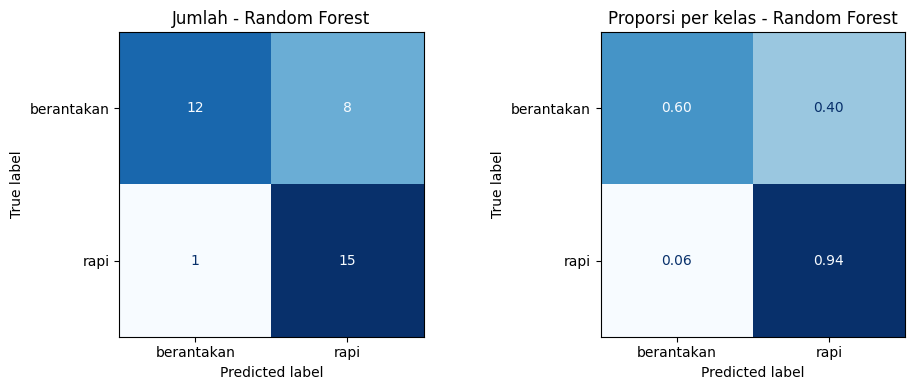

In [47]:
grid_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=100, random_state=42),
    param_grid={"max_depth": [None, 5, 10], "min_samples_leaf": [1, 3, 5]},
    cv=cv, scoring="f1_macro",
)
grid_rf.fit(X_train, y_train, groups=g_train)
model_rf = grid_rf.best_estimator_

print(f"Parameter terbaik : {grid_rf.best_params_}")
print(f"F1 CV ({n_fold}-fold)    : {grid_rf.best_score_:.3f}\n")
evaluasi_model("Random Forest", model_rf)

### 12.2 Support Vector Machine (SVM)

**Cara kerja.** SVM mencari bidang pemisah dengan **margin terlebar** di antara kedua kelas. Dengan kernel **RBF**, data dipetakan ke ruang berdimensi lebih tinggi sehingga batas pemisahnya bisa melengkung:

$$K(\mathbf{x}, \mathbf{x}') = \exp\left(-\gamma\,\lVert\mathbf{x} - \mathbf{x}'\rVert^2\right)$$

- `C` mengatur seberapa keras model menghukum kesalahan pada data latih.
- `gamma` mengatur jangkauan pengaruh setiap titik data.

SVM bekerja dengan jarak, sedangkan skala fitur di sini sangat berbeda (mean berkisar 0–255, sementara korelasi dan homogenitas berkisar 0–1). Karena itu fitur distandardisasi dengan `StandardScaler`, $z = (x - \mu)/\sigma$, di dalam `Pipeline` agar scaler hanya mempelajari $\mu$ dan $\sigma$ dari data latih pada setiap fold.

Parameter terbaik : {'svm__C': 100, 'svm__gamma': 0.01}
F1 CV (5-fold)    : 0.632

Akurasi data uji : 0.833

              precision    recall  f1-score   support

  berantakan      1.000     0.700     0.824        20
        rapi      0.727     1.000     0.842        16

    accuracy                          0.833        36
   macro avg      0.864     0.850     0.833        36
weighted avg      0.879     0.833     0.832        36

Confusion matrix (baris = sebenarnya, kolom = prediksi):
                       prediksi berantakan  prediksi rapi
sebenarnya berantakan                   14              6
sebenarnya rapi                          0             16


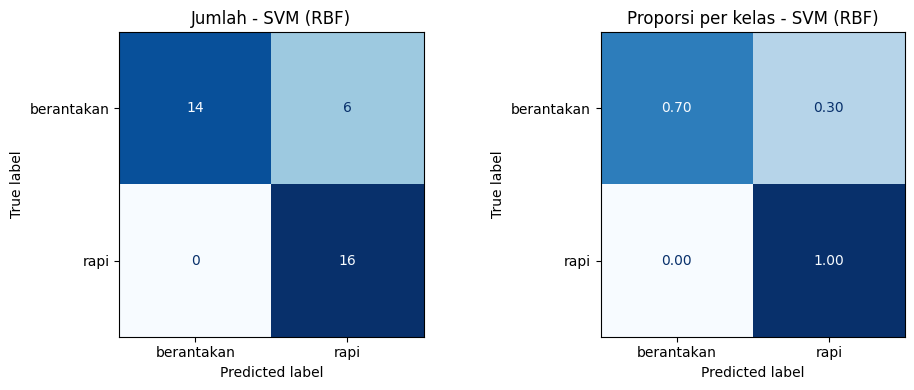

In [48]:
grid_svm = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf", random_state=42))]),
    param_grid={"svm__C": [0.1, 1, 10, 100], "svm__gamma": ["scale", 0.01, 0.1]},
    cv=cv, scoring="f1_macro",
)
grid_svm.fit(X_train, y_train, groups=g_train)
model_svm = grid_svm.best_estimator_

print(f"Parameter terbaik : {grid_svm.best_params_}")
print(f"F1 CV ({n_fold}-fold)    : {grid_svm.best_score_:.3f}\n")
evaluasi_model("SVM (RBF)", model_svm)

### 12.3 K-Nearest Neighbors (KNN)

**Cara kerja.** Untuk memprediksi satu gambar baru, KNN mencari $k$ gambar latih yang **paling dekat** dengannya, lalu mengambil kelas mayoritas dari tetangga-tetangga itu. Jarak yang dipakai adalah jarak Euclidean:

$$d(\mathbf{x}, \mathbf{x}') = \sqrt{\sum_{j=1}^{14}(x_j - x'_j)^2}$$

Seperti SVM, KNN sangat bergantung pada skala, sehingga juga memakai `StandardScaler`. Parameter yang di-*tuning* adalah `n_neighbors` dan `weights` (`uniform` atau `distance`).

Parameter terbaik : {'knn__n_neighbors': 15, 'knn__weights': 'uniform'}
F1 CV (5-fold)    : 0.655

Akurasi data uji : 0.722

              precision    recall  f1-score   support

  berantakan      0.812     0.650     0.722        20
        rapi      0.650     0.812     0.722        16

    accuracy                          0.722        36
   macro avg      0.731     0.731     0.722        36
weighted avg      0.740     0.722     0.722        36

Confusion matrix (baris = sebenarnya, kolom = prediksi):
                       prediksi berantakan  prediksi rapi
sebenarnya berantakan                   13              7
sebenarnya rapi                          3             13


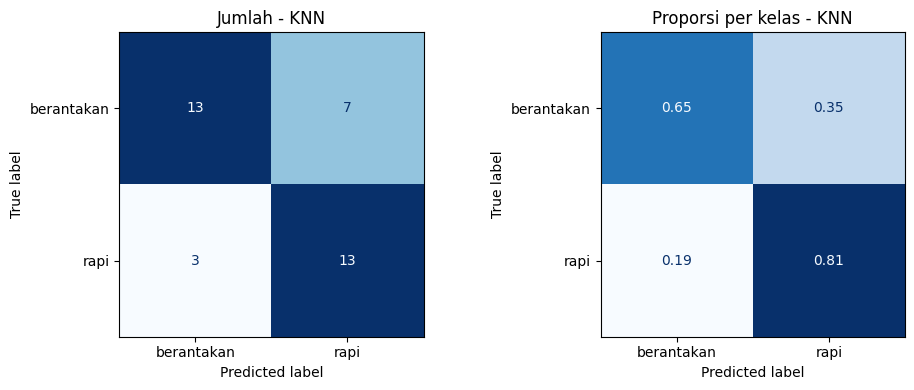

In [49]:
grid_knn = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())]),
    param_grid={"knn__n_neighbors": [3, 5, 7, 9, 11, 15], "knn__weights": ["uniform", "distance"]},
    cv=cv, scoring="f1_macro",
)
grid_knn.fit(X_train, y_train, groups=g_train)
model_knn = grid_knn.best_estimator_

print(f"Parameter terbaik : {grid_knn.best_params_}")
print(f"F1 CV ({n_fold}-fold)    : {grid_knn.best_score_:.3f}\n")
evaluasi_model("KNN", model_knn)

### 12.4 Gaussian Naive Bayes

**Cara kerja.** Memakai teorema Bayes dengan asumsi setiap fitur saling bebas dan berdistribusi normal di dalam tiap kelas. Sangat cepat dan hampir tanpa parameter, tapi asumsi bebasnya kurang cocok untuk fitur yang saling berkorelasi (misalnya `mean_r/g/b`). Parameter yang di-*tuning* adalah `var_smoothing`.

Parameter terbaik : {'nb__var_smoothing': 0.1}
F1 CV (5-fold)    : 0.561

Akurasi data uji : 0.750

              precision    recall  f1-score   support

  berantakan      0.923     0.600     0.727        20
        rapi      0.652     0.938     0.769        16

    accuracy                          0.750        36
   macro avg      0.788     0.769     0.748        36
weighted avg      0.803     0.750     0.746        36

Confusion matrix (baris = sebenarnya, kolom = prediksi):
                       prediksi berantakan  prediksi rapi
sebenarnya berantakan                   12              8
sebenarnya rapi                          1             15


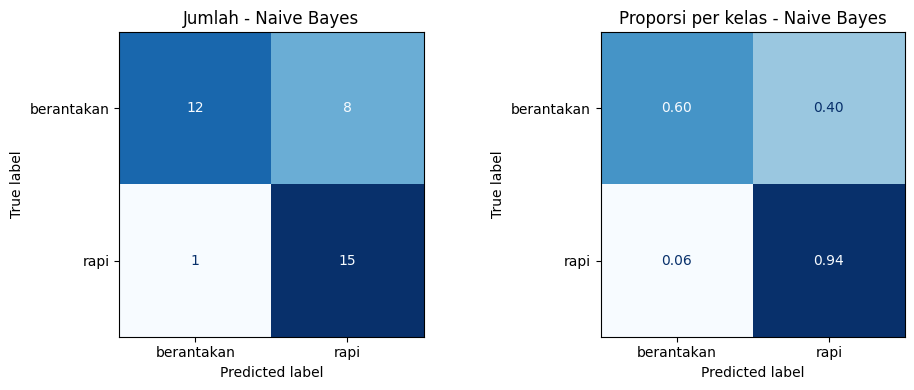

In [52]:
grid_nb = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("nb", GaussianNB())]),
    param_grid={"nb__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-1]},
    cv=cv, scoring="f1_macro",
)
grid_nb.fit(X_train, y_train, groups=g_train)
model_nb = grid_nb.best_estimator_

print(f"Parameter terbaik : {grid_nb.best_params_}")
print(f"F1 CV ({n_fold}-fold)    : {grid_nb.best_score_:.3f}\n")
evaluasi_model("Naive Bayes", model_nb)

## 13. Evaluasi

### 13.1 Perbandingan Semua Metode

**F1 CV** adalah rata-rata fold pada data latih, sedangkan kolom lainnya diukur pada data uji.

In [63]:
models = {"Random Forest": model_rf, "SVM (RBF)": model_svm, "KNN": model_knn,
          "Naive Bayes": model_nb}
grids = {"Random Forest": grid_rf, "SVM (RBF)": grid_svm, "KNN": grid_knn,
         "Naive Bayes": grid_nb}

ringkasan = []
for nama, model in models.items():
    pred = model.predict(X_test)
    ringkasan.append({
        "Metode": nama,
        "F1 CV (latih)": grids[nama].best_score_,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 (uji)": f1_score(y_test, pred, average="macro", zero_division=0),
    })

perbandingan = pd.DataFrame(ringkasan).set_index("Metode").round(3).sort_values("F1 (uji)", ascending=False)
perbandingan.to_csv(os.path.join(FOLDER_OUTPUT, "perbandingan_model.csv"))
perbandingan

,F1 CV (latih),Accuracy,Precision,Recall,F1 (uji)
Metode,,,,,
SVM (RBF),0.632,0.833,0.864,0.850,0.833
Random Forest,0.645,0.750,0.788,0.769,0.748
Naive Bayes,0.561,0.750,0.788,0.769,0.748
KNN,0.655,0.722,0.731,0.731,0.722


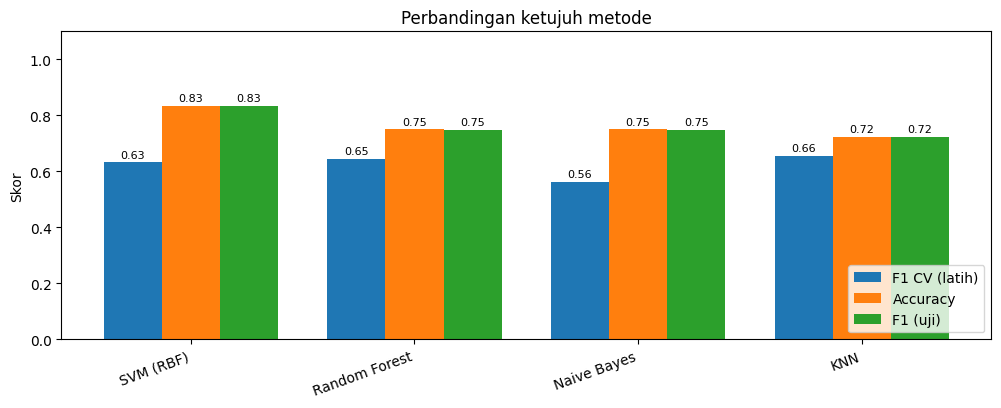

In [64]:
metrik = ["F1 CV (latih)", "Accuracy", "F1 (uji)"]
posisi = np.arange(len(perbandingan))
lebar = 0.26

fig, ax = plt.subplots(figsize=(12, 4))
for i, m in enumerate(metrik):
    batang = ax.bar(posisi + (i - 1) * lebar, perbandingan[m], lebar, label=m)
    ax.bar_label(batang, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(posisi, perbandingan.index, rotation=20, ha="right")
ax.set(ylim=(0, 1.1), ylabel="Skor", title="Perbandingan ketujuh metode")
ax.legend(loc="lower right")
plt.show()

### 13.2 Confusion Matrix Semua Metode

Semua *confusion matrix* ditampilkan berdampingan supaya jumlah kesalahan tiap metode mudah dibandingkan.

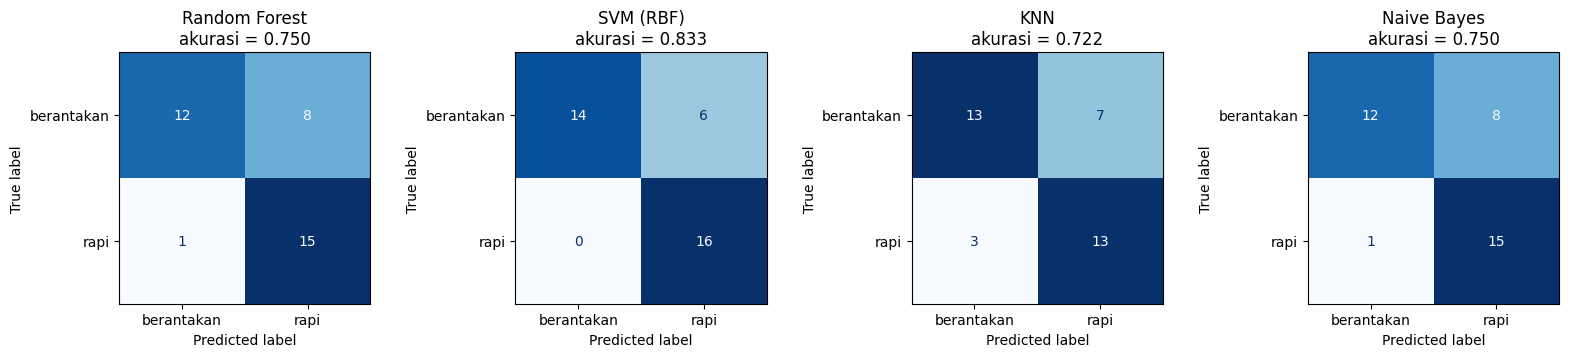

In [65]:

kolom = 4
baris = int(np.ceil(len(models) / kolom))
fig, axes = plt.subplots(baris, kolom, figsize=(4 * kolom, 3.6 * baris))
axes = np.atleast_1d(axes).ravel()
for ax, (nama, model) in zip(axes, models.items()):
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred, labels=KELAS)
    ConfusionMatrixDisplay(cm, display_labels=KELAS).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{nama}\nakurasi = {accuracy_score(y_test, pred):.3f}")
for ax in axes[len(models):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


### 13.3 Feature Importance

*Feature importance* menjawab pertanyaan: **fitur mana yang paling diandalkan model?** Dua cara dipakai:

1. **Gini importance (`feature_importances_`)** bawaan Random Forest.
2. **Permutation importance** untuk semua model. Nilai satu fitur di data uji diacak, lalu diukur seberapa besar akurasi turun. Makin besar penurunannya, makin penting fitur tersebut. Cara ini dipakai karena SVM dan KNN tidak punya `feature_importances_` bawaan.

Jika data uji kecil, satu prediksi yang berubah sudah menggeser akurasi cukup besar, jadi nilai permutation importance yang kecil atau negatif wajar terjadi.

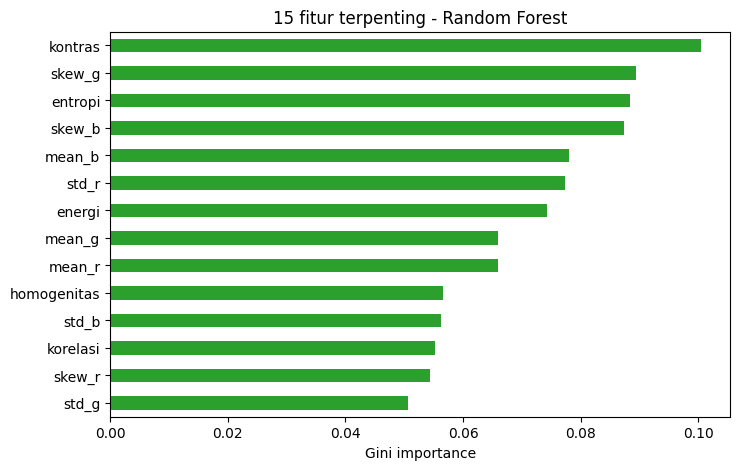

kontras    0.100
skew_g     0.089
entropi    0.088
skew_b     0.087
mean_b     0.078
dtype: float64

In [66]:
gini = pd.Series(model_rf.feature_importances_, index=FITUR).sort_values().tail(15)   # 15 teratas

fig, ax = plt.subplots(figsize=(8, 5))
gini.plot.barh(ax=ax, color="tab:green")
ax.set(xlabel="Gini importance", title="15 fitur terpenting - Random Forest")
plt.show()

gini.sort_values(ascending=False).head(5).round(3)

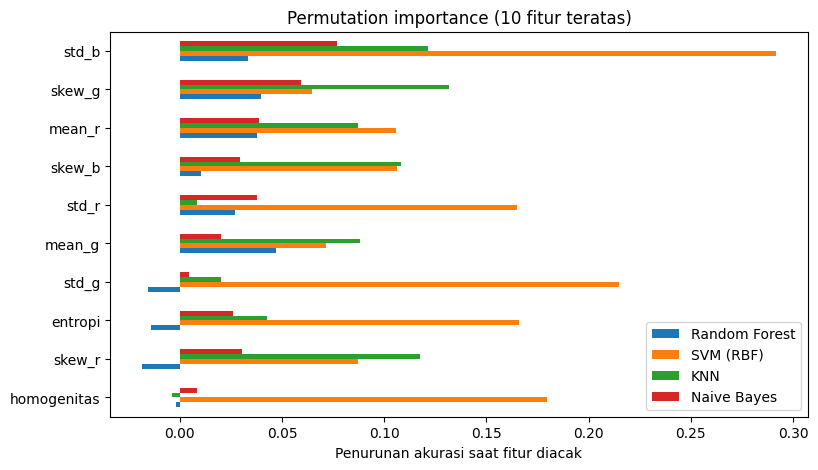

,Random Forest,SVM (RBF),KNN,Naive Bayes
std_b,0.033,0.292,0.121,0.077
skew_g,0.040,0.065,0.131,0.059
mean_r,0.038,0.106,0.087,0.039
skew_b,0.010,0.106,0.108,0.030
std_r,0.027,0.165,0.008,0.038


In [67]:
from sklearn.inspection import permutation_importance

perm = {}
for nama, model in models.items():
    hasil = permutation_importance(model, X_test, y_test, n_repeats=30,
                                   random_state=42, scoring="accuracy")
    perm[nama] = pd.Series(hasil.importances_mean, index=FITUR)
perm = pd.DataFrame(perm)

teratas = perm.mean(axis=1).sort_values(ascending=False).head(10).index
fig, ax = plt.subplots(figsize=(9, 5))
perm.loc[teratas[::-1]].plot.barh(ax=ax)
ax.set(xlabel="Penurunan akurasi saat fitur diacak", title="Permutation importance (10 fitur teratas)")
plt.show()

perm.loc[teratas].round(3).head(5)

### 13.4 Penentuan Metode Terbaik

Metode terbaik ditentukan dari **F1 makro pada data uji**, karena data uji mewakili gambar baru yang belum pernah dilihat model. Jika skornya sama, dipilih metode dengan F1 CV lebih tinggi karena lebih stabil di berbagai pembagian data.

In [68]:
urut = perbandingan.sort_values(["F1 (uji)", "F1 CV (latih)"], ascending=False)
METODE_TERBAIK = urut.index[0]
model_terbaik = models[METODE_TERBAIK]

print(f"Metode terbaik : {METODE_TERBAIK}")
print(f"F1 uji         : {urut.loc[METODE_TERBAIK, 'F1 (uji)']:.3f}")
print(f"Accuracy uji   : {urut.loc[METODE_TERBAIK, 'Accuracy']:.3f}")

urut

Metode terbaik : SVM (RBF)
F1 uji         : 0.833
Accuracy uji   : 0.833


,F1 CV (latih),Accuracy,Precision,Recall,F1 (uji)
Metode,,,,,
SVM (RBF),0.632,0.833,0.864,0.850,0.833
Random Forest,0.645,0.750,0.788,0.769,0.748
Naive Bayes,0.561,0.750,0.788,0.769,0.748
KNN,0.655,0.722,0.731,0.731,0.722


## 14. Pembuktian

Bab ini membandingkan model yang hanya memakai **14 fitur asli** dengan model yang memakai **semua fitur**. Datanya kecil, jadi satu kali split 80:20 hasilnya kurang stabil. Dipakai cross validation berulang pada seluruh data dengan dua cara:

- **Repeated Stratified 5-Fold (3 kali ulang)**: akurasi dirata-rata dari 15 pembagian berbeda.
- **Stratified Group K-Fold**: foto satu grup tidak terpisah antara data latih dan uji (lebih jujur).

### 14.1 Hasil Perbandingan


In [72]:
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedGroupKFold, cross_val_score

def buat_model():
    return {
        "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=42),
        "SVM (RBF)":           Pipeline([("sc", StandardScaler()), ("m", SVC(C=3))]),
        "KNN":                 Pipeline([("sc", StandardScaler()), ("m", KNeighborsClassifier(n_neighbors=5))]),
        "Naive Bayes":         Pipeline([("sc", StandardScaler()), ("m", GaussianNB())]),
    }

kumpulan_fitur = {
    "14 fitur asli": dataset[FITUR_ASLI],
    "semua fitur": pd.concat([dataset[FITUR_ASLI].reset_index(drop=True), tambahan.reset_index(drop=True)], axis=1),
}

cv_acak = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
baris = []
for nama_set, Xs in kumpulan_fitur.items():
    for nama_model, model in buat_model().items():
        a = cross_val_score(model, Xs, y, cv=cv_acak).mean()
        g = np.mean([cross_val_score(model, Xs, y, groups=grup,
                                     cv=StratifiedGroupKFold(5, shuffle=True, random_state=s)).mean()
                     for s in range(3)])
        baris.append({"Fitur": nama_set, "Metode": nama_model, "Akurasi CV acak": a, "Akurasi CV per-grup": g})

hasil_cv = pd.DataFrame(baris).round(3)
hasil_cv.to_csv(os.path.join(FOLDER_OUTPUT, "perbandingan_fitur.csv"), index=False)
hasil_cv

,Fitur,Metode,Akurasi CV acak,Akurasi CV per-grup
0,14 fitur asli,Random Forest,0.710,0.658
1,14 fitur asli,SVM (RBF),0.667,0.672
2,14 fitur asli,KNN,0.648,0.611
3,14 fitur asli,Naive Bayes,0.579,0.563
4,semua fitur,Random Forest,0.778,0.738
5,semua fitur,SVM (RBF),0.833,0.774
6,semua fitur,KNN,0.789,0.755
7,semua fitur,Naive Bayes,0.627,0.611


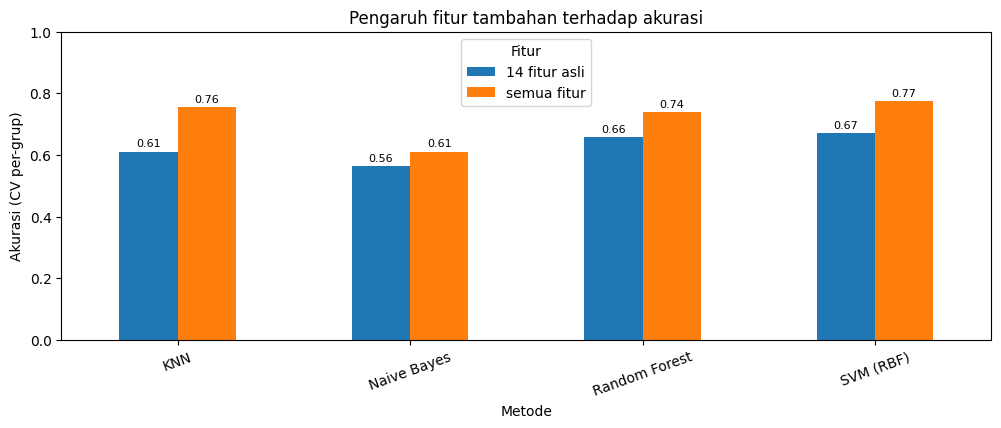

In [73]:
pivot = hasil_cv.pivot(index="Metode", columns="Fitur", values="Akurasi CV per-grup")
ax = pivot.plot.bar(figsize=(12, 4), rot=20)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
ax.set(ylim=(0, 1), ylabel="Akurasi (CV per-grup)", title="Pengaruh fitur tambahan terhadap akurasi")
plt.show()

### 14.2 Confusion Matrix dengan Semua Fitur

Prediksi diambil dengan `cross_val_predict` (Stratified Group K-Fold), sehingga **setiap gambar diprediksi oleh model yang tidak pernah melihat grupnya**. Hasilnya confusion matrix dari seluruh dataset, lebih stabil daripada dari data uji yang kecil.

Metode terbaik (CV per-grup, fitur lengkap): SVM (RBF)
Akurasi: 0.768

              precision    recall  f1-score   support

  berantakan      0.771     0.763     0.767        97
        rapi      0.765     0.773     0.769        97

    accuracy                          0.768       194
   macro avg      0.768     0.768     0.768       194
weighted avg      0.768     0.768     0.768       194



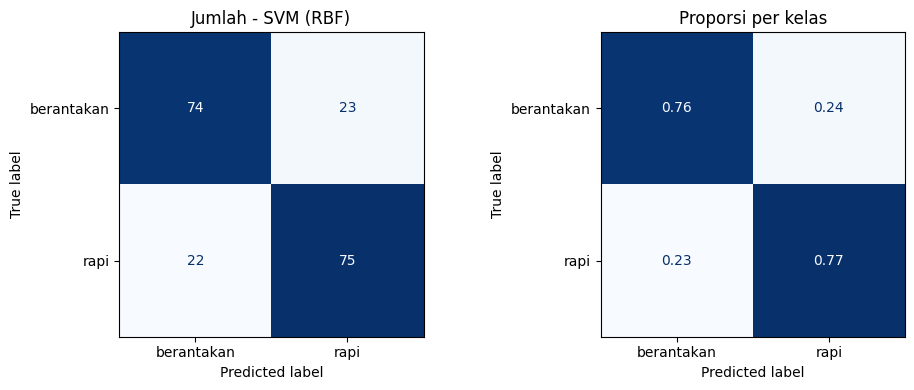

In [74]:
from sklearn.model_selection import cross_val_predict

X_lengkap = kumpulan_fitur["semua fitur"]
terbaik = hasil_cv[hasil_cv["Fitur"] == "semua fitur"].sort_values("Akurasi CV per-grup").iloc[-1]["Metode"]
print("Metode terbaik (CV per-grup, fitur lengkap):", terbaik)

pred = cross_val_predict(buat_model()[terbaik], X_lengkap, y, groups=grup,
                         cv=StratifiedGroupKFold(5, shuffle=True, random_state=0))
print(f"Akurasi: {accuracy_score(y, pred):.3f}\n")
print(classification_report(y, pred, labels=KELAS, digits=3))

cm = confusion_matrix(y, pred, labels=KELAS)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cm, display_labels=KELAS).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Jumlah - {terbaik}")
ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=KELAS, normalize="true"),
                       display_labels=KELAS).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Proporsi per kelas")
plt.tight_layout(); plt.show()